In [7]:
import numpy as np
import pyccl as ccl
from scipy.special import erf
import matplotlib.pyplot as plt
from itertools import combinations_with_replacement

In [1]:
14300 / 41253.

0.34664145637893

In [8]:
SURVEY = {  # parámetros del LSST DESC SRD
    "Y10": dict(z0=0.11, alpha=0.68, neff=30.0, fsky=0.35),
}

In [9]:
CFG = dict(
    survey="Y10", nbins=5, sigma_z0=0.05, sigma_e=0.26,
    A_IA=0.0,                        # 0 -> sin alineamientos intrínsecos
    ell_min=20, ell_max=3000, n_ell=20,
    transfer="boltzmann_camb",      # usa "eisenstein_hu" si no tienes CAMB
    # --- P(k, a) propio ---
    pk_mode="modified",   # "ccl" (halofit estándar) | "modified" (halofit x S(k,a)) | "external" (archivo)
    pk_file="pk_external.npz",       # para "external": claves k, z, pk  (pk con shape (n_z, n_k))
    pk_h_units=False,                # True si el archivo está en k [h/Mpc], P [(Mpc/h)^3]
    n_a=60, k_min=1e-4, k_max=50.0, n_k=400,   # grilla para "modified" (k en 1/Mpc)
)
COSMO = dict(Omega_c=0.2664, Omega_b=0.0492, h=0.6727, sigma8=0.831, n_s=0.9645)


In [10]:
# ---------------- n(z) ----------------
def smail_nz(z, z0, alpha):
    nz = z**2 * np.exp(-(z / z0)**alpha)
    return nz / np.trapz(nz, z)


def tomographic_nz(z, nz, nbins, sigma_z0):
    """Bordes de igual número en z verdadero; cada bin convolucionado con
    photo-z gaussiano de ancho sigma_z0 (1+z)."""
    cdf = np.cumsum(nz); cdf /= cdf[-1]
    edges = np.interp(np.linspace(0, 1, nbins + 1), cdf, z)
    sig = sigma_z0 * (1 + z)
    bins = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        w = 0.5 * (erf((hi - z) / (np.sqrt(2) * sig)) - erf((lo - z) / (np.sqrt(2) * sig)))
        n_i = nz * w
        bins.append(n_i / np.trapz(n_i, z))
    return edges, np.array(bins)


# ---------------- P(k, a) ----------------
def pk_modifier(k, a):
    """S(k, a) que multiplica al P(k) no lineal. k en 1/Mpc, a escalar.
    Ejemplo de juguete: supresión de 20% a k >~ 1/Mpc. Reemplázalo por tu modelo."""
    return 1 - 0.2 / (1 + (k / 1.0)**-2)


def build_pk(cosmo, cfg, z_max):
    """Devuelve un ccl.Pk2D (o None para usar el P(k) por defecto de la cosmología).
    Convención de CCL: k en 1/Mpc, P en Mpc^3, a creciente."""
    mode = cfg["pk_mode"]
    if mode == "ccl":
        return None

    if mode == "modified":
        a = np.linspace(1 / (1 + z_max), 1, cfg["n_a"])
        k = np.geomspace(cfg["k_min"], cfg["k_max"], cfg["n_k"])
        pk0 = cosmo.get_nonlin_power()
        P = np.array([pk0(k, ai) * pk_modifier(k, ai) for ai in a])

    elif mode == "external":
        d = np.load(cfg["pk_file"])
        k, zp, P = d["k"], d["z"], d["pk"]
        if cfg["pk_h_units"]:
            h = cosmo["h"]
            k, P = k * h, P / h**3
        a = 1 / (1 + zp)
        idx = np.argsort(a)                      # CCL exige a creciente
        a, P = a[idx], P[idx]
        if a.min() > 1 / (1 + z_max):
            print(f"AVISO: P(k) externo llega solo a z={1/a.min()-1:.2f} < z_max={z_max:.2f}; CCL extrapolará.")
    else:
        raise ValueError(f"pk_mode desconocido: {mode}")

    if np.any(P <= 0):
        raise ValueError("P(k) debe ser positivo para interpolar en log.")
    return ccl.Pk2D(a_arr=a, lk_arr=np.log(k), pk_arr=np.log(P), is_logp=True)



Bordes en z: [1.000e-03 4.480e-01 7.130e-01 1.027e+00 1.506e+00 3.500e+00]
S/N total (Y10): 648.2
Delta chi2 vs P(k) estándar (modified): 5191.2


/var/folders/20/2r9ht6p119lgrj4m0ywn44_00000gn/T/ipykernel_6394/1894434913.py:72: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.clf()
/var/folders/20/2r9ht6p119lgrj4m0ywn44_00000gn/T/ipykernel_6394/1894434913.py:72: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.clf()


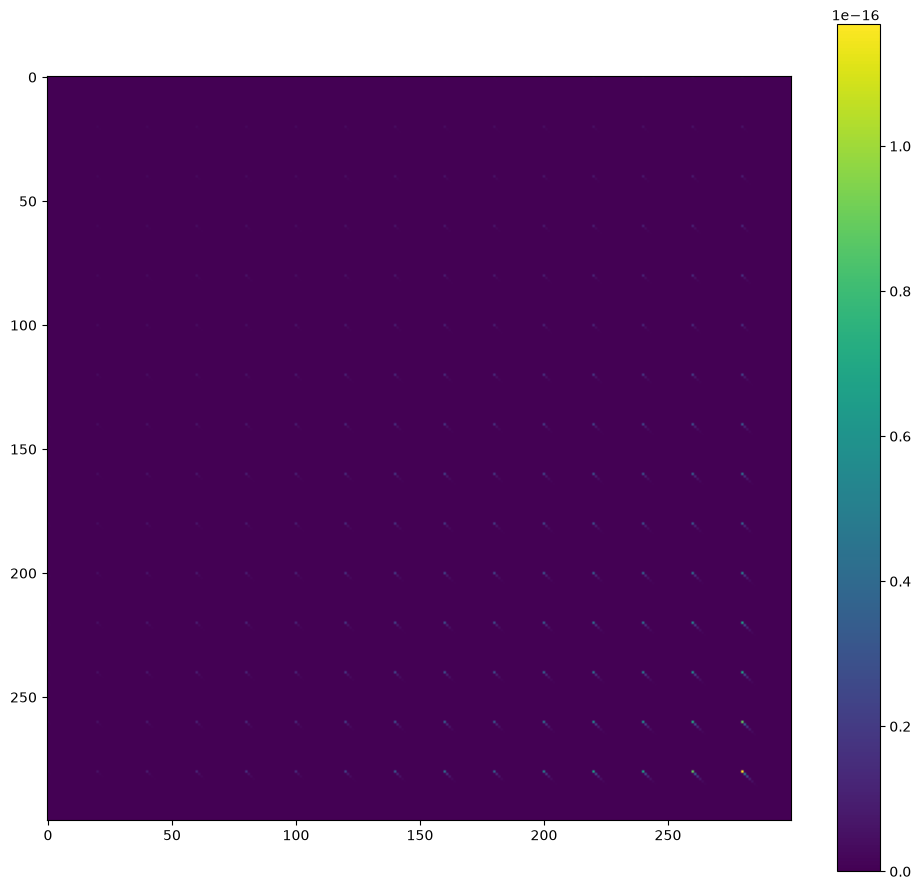

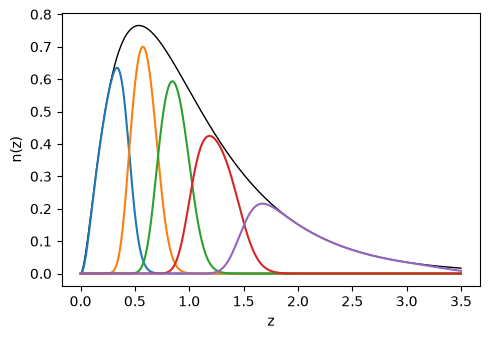

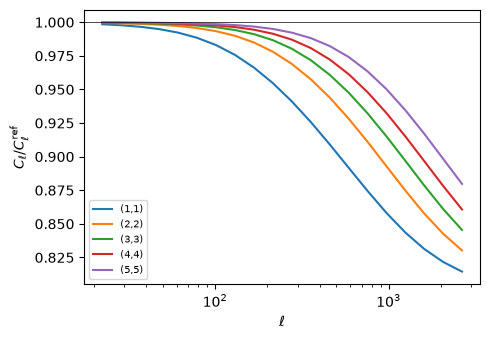

In [13]:
# ---------------- Pipeline ----------------
def run(cfg=CFG, cosmo_pars=COSMO):
    sv = SURVEY[cfg["survey"]]
    cosmo = ccl.Cosmology(**cosmo_pars, transfer_function=cfg["transfer"],
                          matter_power_spectrum="halofit")

    z = np.linspace(1e-3, 3.5, 700)
    nz = smail_nz(z, sv["z0"], sv["alpha"])
    edges, nz_bins = tomographic_nz(z, nz, cfg["nbins"], cfg["sigma_z0"])

    ia = (z, cfg["A_IA"] * np.ones_like(z)) if cfg["A_IA"] else None
    tracers = [ccl.WeakLensingTracer(cosmo, dndz=(z, n), ia_bias=ia) for n in nz_bins]

    # Bandas logarítmicas
    ell_edges = np.unique(np.geomspace(cfg["ell_min"], cfg["ell_max"], cfg["n_ell"] + 1).astype(int))
    ell = np.sqrt(ell_edges[:-1] * ell_edges[1:])
    dell = np.diff(ell_edges)

    pk = build_pk(cosmo, cfg, z.max())

    nb = cfg["nbins"]
    cl = np.zeros((nb, nb, ell.size))
    cl_ref = np.zeros_like(cl)                   # con el P(k) estándar, para comparar
    for i, j in combinations_with_replacement(range(nb), 2):
        cl[i, j] = cl[j, i] = ccl.angular_cl(cosmo, tracers[i], tracers[j], ell, p_of_k_a=pk)
        cl_ref[i, j] = cl_ref[j, i] = (cl[i, j] if pk is None else
                                       ccl.angular_cl(cosmo, tracers[i], tracers[j], ell))

    # Ruido de forma: sigma_e^2 / n_i, n_i = neff/nbins (bins de igual número)
    n_i = sv["neff"] / nb * (180 * 60 / np.pi)**2       # arcmin^-2 -> sr^-1
    noise = np.zeros_like(cl)
    for i in range(nb):
        noise[i, i] = cfg["sigma_e"]**2 / n_i
    cl_tot = cl + noise

    # Covarianza gaussiana en el vector de datos (pares i<=j, ell)
    pairs = list(combinations_with_replacement(range(nb), 2))
    npair, nl = len(pairs), ell.size
    cov = np.zeros((npair * nl, npair * nl))
    pref = 1.0 / ((2 * ell + 1) * dell * sv["fsky"])
    for a, (i, j) in enumerate(pairs):
        for b, (k, l) in enumerate(pairs):
            c = pref * (cl_tot[i, k] * cl_tot[j, l] + cl_tot[i, l] * cl_tot[j, k])
            cov[a * nl + np.arange(nl), b * nl + np.arange(nl)] = c
    dvec = np.concatenate([cl[i, j] for i, j in pairs])
    snr = np.sqrt(dvec @ np.linalg.solve(cov, dvec))
    # Distinguibilidad respecto al P(k) estándar (misma covarianza)
    diff = dvec - np.concatenate([cl_ref[i, j] for i, j in pairs])
    dchi2 = diff @ np.linalg.solve(cov, diff)

    return dict(cosmo=cosmo, pk=pk, z=z, nz=nz, edges=edges, nz_bins=nz_bins, ell=ell,
                ell_edges=ell_edges, cl=cl, cl_ref=cl_ref, noise=noise, pairs=pairs,
                dvec=dvec, cov=cov, snr=snr, dchi2=dchi2)


def plot(res, fname="wl_cls.png"):
    nb = res["cl"].shape[0]; ell = res["ell"]
    fig, ax = plt.subplots(nb, nb, figsize=(2.4 * nb, 2.2 * nb), sharex=True, sharey=True)
    err = np.sqrt(np.diag(res["cov"])).reshape(len(res["pairs"]), -1)
    for a, (i, j) in enumerate(res["pairs"]):
        p = ell * (ell + 1) / (2 * np.pi)
        ax[j, i].errorbar(ell, p * res["cl"][i, j], p * err[a], fmt=".-", ms=3)
        if i == j:
            ax[j, i].plot(ell, p * res["noise"][i, i], "k:", lw=1)
        ax[j, i].text(0.05, 0.85, f"({i+1},{j+1})", transform=ax[j, i].transAxes, fontsize=8)
        ax[i, j].set_visible(i == j)
    for a_ in ax.flat:
        a_.set_xscale("log"); a_.set_yscale("log")
    fig.supxlabel(r"$\ell$"); fig.supylabel(r"$\ell(\ell+1)C_\ell/2\pi$")
    fig.tight_layout(); fig.savefig(fname, dpi=150)

    plt.clf()
    
    covmat=res['cov']
    plt.imshow(covmat)
    plt.colorbar()
    plt.show()

    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.plot(res["z"], res["nz"], "k", lw=1)
    for n in res["nz_bins"]:
        ax.plot(res["z"], n / len(res["nz_bins"]))
    ax.set_xlabel("z"); ax.set_ylabel("n(z)")
    fig.tight_layout(); fig.savefig("wl_nz.png", dpi=150)

    if res["pk"] is not None:                    # cociente C_ell(P propio) / C_ell(estándar)
        fig, ax = plt.subplots(figsize=(5, 3.5))
        for i in range(nb):
            ax.plot(ell, res["cl"][i, i] / res["cl_ref"][i, i], label=f"({i+1},{i+1})")
        ax.axhline(1, c="k", lw=0.5); ax.set_xscale("log")
        ax.set_xlabel(r"$\ell$"); ax.set_ylabel(r"$C_\ell / C_\ell^{\rm ref}$"); ax.legend(fontsize=7)
        fig.tight_layout(); fig.savefig("wl_cl_ratio.png", dpi=150)


if __name__ == "__main__":
    res = run()
    print(f"Bordes en z: {np.round(res['edges'], 3)}")
    print(f"S/N total ({CFG['survey']}): {res['snr']:.1f}")
    if res["pk"] is not None:
        print(f"Delta chi2 vs P(k) estándar ({CFG['pk_mode']}): {res['dchi2']:.1f}")
    plot(res)
    np.savez("wl_cls.npz", ell=res["ell"], ell_edges=res["ell_edges"], cl=res["cl"], cl_ref=res["cl_ref"],
             noise=res["noise"], dvec=res["dvec"], cov=res["cov"],
             z=res["z"], nz_bins=res["nz_bins"])
